# Analisis Perbandingan Kinerja Fast MTCNN dan MediaPipe
## dalam Deteksi Wajah pada Dataset DPO Bareskrim

---

**Mata Kuliah**: Pengolahan Citra Digital (PCD)  
**Dataset**: DPO Bareskrim Polri — 12 Citra Asli  
**Metode Evaluasi**: Precision, Recall, F1-Score, Average IoU, Latency (ms), FPS  

---

## Abstrak

Penelitian ini melakukan analisis komparatif empiris terhadap dua arsitektur detektor wajah modern:
**Fast MTCNN** (Multi-Task Cascaded Convolutional Networks) dan **MediaPipe Face Detection**
(berbasis BlazeFace). Eksperimen dilakukan pada dataset primer berupa 12 foto DPO Bareskrim
yang diperluas menjadi 120 citra melalui pipeline augmentasi data berbasis `albumentations`
yang mempertahankan sinkronisasi koordinat bounding box ground truth secara otomatis.
Evaluasi mencakup metrik kuantitatif (Precision, Recall, F1-Score, Average IoU) dan
metrik komputasi (Latency, Throughput/FPS) serta analisis breakdown per tipe augmentasi.

## Struktur Notebook

| Cell | Konten |
|------|--------|
| 1 | Environment Setup & Dependencies |
| 2 | Dataset Loader & Ground Truth Initialization |
| 3 | Exploratory Data Analysis (EDA) Citra Asli |
| 4 | Pipeline Augmentasi Data (Bounding Box-Preserving) |
| 5 | EDA Pasca-Augmentasi & Verifikasi Integritas |
| 6 | Wrapper & Standarisasi Model Detektor |
| 7 | Metrik Evaluasi & Benchmarking Engine |
| 8 | Analisis Kuantitatif & Tabel Komparasi |
| 9 | Visualisasi Hasil Kualitatif & Analisis Error |
| 10 | Ekspor Hasil Penelitian |

---
## Cell 1: Environment Setup & Dependencies

Instalasi seluruh dependensi yang diperlukan untuk eksperimen.  
Eksperimen dikunci dengan **`random seed = 42`** untuk menjamin **reproducibility** penuh.

> **Catatan Kompatibilitas**:
> - `mediapipe >= 0.10` — API `face_detection` mungkin berbeda dari versi lama; kode ini kompatibel dengan keduanya.
> - `facenet-pytorch` memerlukan `torch` (CPU/CUDA); deteksi CUDA otomatis.
> - `albumentations >= 1.3` diperlukan untuk `BboxParams` yang stabil.

In [1]:
# ============================================================
# CELL 1A: INSTALASI LIBRARY (jalankan sekali, lalu bisa di-comment)
# ============================================================
import subprocess, sys

packages = [
    'mediapipe',
    'facenet-pytorch',
    'albumentations>=1.3.0',
    'opencv-python',
    'pandas',
    'seaborn',
    'matplotlib',
    'scikit-learn',
    'Pillow',
    'tqdm',
    'torch',
    'torchvision',
]

print('Installing dependencies...')
for pkg in packages:
    result = subprocess.run(
        [sys.executable, '-m', 'pip', 'install', pkg, '-q'],
        capture_output=True, text=True
    )
    status = '✅' if result.returncode == 0 else '❌'
    print(f'  {status} {pkg}')

print('\n✅ Instalasi selesai.')

Installing dependencies...


  ✅ mediapipe


  ✅ facenet-pytorch


  ✅ albumentations>=1.3.0


  ✅ opencv-python


...

  ✅ scikit-learn


  ✅ Pillow


  ✅ tqdm


  ✅ torch


  ✅ torchvision

✅ Instalasi selesai.


In [2]:
# ============================================================
# CELL 1B: IMPORT LIBRARY & KONFIGURASI GLOBAL
# ============================================================
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
import cv2
import json
import time
import random
import shutil
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image
from tqdm import tqdm
from collections import defaultdict
from dataclasses import dataclass, field
from typing import List, Optional

# Augmentasi
import albumentations as A
from albumentations.core.composition import BboxParams

warnings.filterwarnings('ignore')

# -------------------------------------------------------
# REPRODUCIBILITY SEED
# -------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# -------------------------------------------------------
# SPESIFIKASI SISTEM & HARDWARE (Untuk Reproducibility Jurnal)
# -------------------------------------------------------
import platform
import psutil
import subprocess

def get_hardware_info():
    cpu_name = platform.processor()
    try:
        cmd = ['powershell', '-Command', 'Get-CimInstance Win32_Processor | Select-Object -ExpandProperty Name']
        res = subprocess.run(cmd, capture_output=True, text=True)
        if res.returncode == 0 and res.stdout.strip():
            cpu_name = res.stdout.strip()
    except Exception:
        pass
    
    try:
        build = int(platform.version().split('.')[2])
        os_ver = f"{platform.system()} 11" if build >= 22000 else f"{platform.system()} {platform.release()}"
    except Exception:
        os_ver = f"{platform.system()} {platform.release()}"

    ram_gb = round(psutil.virtual_memory().total / (1024**3), 2)
    
    return {
        'cpu_model': cpu_name,
        'cpu_cores_physical': psutil.cpu_count(logical=False),
        'cpu_cores_logical': psutil.cpu_count(logical=True),
        'ram_total_gb': ram_gb,
        'os': f"{os_ver} ({platform.architecture()[0]})",
        'python_version': platform.python_version()
    }

SYSTEM_INFO = get_hardware_info()

# -------------------------------------------------------
# DEKLARASI DIREKTORI
# -------------------------------------------------------
BASE_DIR = Path(r'D:\Kuliah\Semester 5\PCD\FaceDetection_FastMtCNN_MediaPipe')

# Dataset asli: 12 foto DPO tersebar di subfolder kelompok
DATASET_ROOT = BASE_DIR / 'Dataset PCD 4703 - DPO'

# Direktori output eksperimen
DIR_ORIGINAL  = BASE_DIR / 'dataset' / 'original'
DIR_AUGMENTED = BASE_DIR / 'dataset' / 'augmented'
DIR_RESULTS   = BASE_DIR / 'results'
DIR_PLOTS     = DIR_RESULTS / 'plots'

for d in [DIR_ORIGINAL, DIR_AUGMENTED, DIR_RESULTS, DIR_PLOTS]:
    d.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# KONFIGURASI PLOT
# -------------------------------------------------------
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'DejaVu Sans',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})
PALETTE = {'FastMTCNN': '#3B82F6', 'MediaPipe': '#EF4444', 'GT': '#22C55E'}

print('✅ Konfigurasi lingkungan & hardware siap.')
print(f'   Base Dir      : {BASE_DIR}')
print(f'   Dataset       : {DATASET_ROOT}')
print(f'   Results       : {DIR_RESULTS}')
print(f"   CPU Hardware  : {SYSTEM_INFO['cpu_model']} ({SYSTEM_INFO['cpu_cores_physical']}C/{SYSTEM_INFO['cpu_cores_logical']}T)")
print(f"   Memory (RAM)  : {SYSTEM_INFO['ram_total_gb']} GB")


✅ Konfigurasi lingkungan & hardware siap.
   Base Dir      : D:\Kuliah\Semester 5\PCD\FaceDetection_FastMtCNN_MediaPipe
   Dataset       : D:\Kuliah\Semester 5\PCD\FaceDetection_FastMtCNN_MediaPipe\Dataset PCD 4703 - DPO
   Results       : D:\Kuliah\Semester 5\PCD\FaceDetection_FastMtCNN_MediaPipe\results
   CPU Hardware  : Intel(R) Core(TM) Ultra 7 255HX (20C/20T)
   Memory (RAM)  : 31.43 GB


---
## Cell 2: Inisialisasi Dataset & Ground Truth

### Strategi Anotasi Ground Truth

Karena dataset DPO tidak disertai file anotasi bounding box formal (tidak ada `.xml`/`.json` COCO),
ground truth diinisialisasi melalui dua jalur:

1. **Jalur Primer** — File `ground_truth.json` yang sudah ada (hasil anotasi manual sebelumnya).
2. **Jalur Fallback** — Estimasi otomatis menggunakan OpenCV Haar Cascade sebagai proxy GT awal.
   Hasil kemudian disimpan ke `ground_truth.json` untuk **validasi manual**.

> **PENTING untuk Penelitian Formal**: Bounding box GT yang diestimasi Haar Cascade harus  
> divalidasi/diperbaiki secara manual menggunakan anotator seperti **LabelImg** atau **CVAT**  
> sebelum dianggap sebagai ground truth definitif.

### Format File Ground Truth (`ground_truth.json`)
```json
{
  "dpo_01.jpg": {
    "image_path": "...",
    "width": 640,
    "height": 480,
    "bboxes": [[xmin, ymin, xmax, ymax], ...]
  }
}
```

In [3]:
# ============================================================
# CELL 2A: KUMPULKAN GAMBAR ASLI & STANDARISASI NAMA (AUTO-DISCOVERY)
# ============================================================

VALID_EXT = {'.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG'}

def collect_images(root_dir: Path) -> list:
    """Rekursif kumpulkan semua path gambar asli terurut berdasarkan kelompok."""
    images = []
    group_dirs = sorted([d for d in root_dir.iterdir() if d.is_dir()])
    if group_dirs:
        for g in group_dirs:
            images.extend(sorted([p for p in g.rglob('*') if p.suffix in VALID_EXT]))
    else:
        images = sorted([p for p in root_dir.rglob('*') if p.suffix in VALID_EXT])
    return images

original_image_paths = collect_images(DATASET_ROOT)
print(f'📂 Ditemukan {len(original_image_paths)} citra asli di dataset:')
for i, p in enumerate(original_image_paths, 1):
    print(f'   [{i:02d}] {p.relative_to(DATASET_ROOT)}')


📂 Ditemukan 12 citra asli di dataset:
   [01] Kelompok 1\A11.2023.15150 - Okta Pradipta Vinton\FachriMukhtar_original.jpg
   [02] Kelompok 1\A11.2024.15694 - Farros Rifantiarno Ramadhani\hendraferliza_original.JPG
   [03] Kelompok 1\A11.2024.15754-Rofa Rayan\Kelvin Wiranata.jpg
   [04] Kelompok 1\A11.2024.15961 - Surya Maulana Syaputra\ORIGINAL.jpg
   [05] Kelompok 2\A11.2024.15606 - Nadinta Alqisya.jpeg
   [06] Kelompok 2\A11.2024.15609 - Rafania Putri Mahendra.jpg
   [07] Kelompok 2\A11.2024.15610 - Oryza Sekar Rismadhani.jpg
   [08] Kelompok 2\A11.2024.15618 - Laily Muthia.jpg
   [09] Kelompok 3\A11.2024.15632 - Muhammad Ismail Hadi..jpg
   [10] Kelompok 3\A11.2024.15640 - Baraza Nandian Syah_.jpg
   [11] Kelompok 3\A11.2024.15668 - Muhammad Najib FInanda.jpg
   [12] Kelompok 3\A11.2024.15939 - Ezar Arganta Hibatullah.jpg


In [4]:
# ============================================================
# CELL 2B: SALIN KE DIREKTORI STANDAR (AUTO-SYNC)
# ============================================================
DIR_ORIGINAL.mkdir(parents=True, exist_ok=True)
standardized_paths = {}

# Resinkronisasi otomatis jika jumlah citra berbeda
existing_dpos = sorted(DIR_ORIGINAL.glob('dpo_*.jpg'))
if len(existing_dpos) != len(original_image_paths):
    for old_f in existing_dpos:
        old_f.unlink()

for idx, src_path in enumerate(original_image_paths, 1):
    dst_name = f'dpo_{idx:02d}.jpg'
    dst_path = DIR_ORIGINAL / dst_name
    
    if not dst_path.exists():
        img = cv2.imread(str(src_path))
        if img is not None:
            cv2.imwrite(str(dst_path), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
            standardized_paths[dst_name] = dst_path
        else:
            print(f'  ⚠️  Tidak dapat membaca: {src_path.name}')
    else:
        standardized_paths[dst_name] = dst_path

print(f'✅ {len(standardized_paths)} citra terstandardisasi otomatis ke: {DIR_ORIGINAL}')


✅ 12 citra terstandardisasi otomatis ke: D:\Kuliah\Semester 5\PCD\FaceDetection_FastMtCNN_MediaPipe\dataset\original


In [5]:
# ============================================================
# CELL 2C: BUILD GROUND TRUTH DATABASE (AUTO-INCREMENTAL)
# ============================================================

GT_JSON_PATH = DIR_RESULTS / 'ground_truth.json'


def estimate_gt_with_haar(image_path: Path, min_neighbors: int = 3) -> dict:
    """
    Estimasi bounding box wajah menggunakan Haar Cascade sebagai GT proxy.
    """
    face_cascade = cv2.CascadeClassifier(
        cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
    )
    
    img = cv2.imread(str(image_path))
    if img is None:
        raise FileNotFoundError(f'Tidak dapat membaca: {image_path}')
    
    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.equalizeHist(gray)
    
    faces = face_cascade.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=min_neighbors,
        minSize=(30, 30), flags=cv2.CASCADE_SCALE_IMAGE
    )
    
    bboxes = []
    if len(faces) > 0:
        # Ambil wajah terbesar (portrait DPO)
        largest_face = max(faces, key=lambda f: f[2] * f[3])
        x, y, fw, fh = largest_face
        bboxes.append([int(x), int(y), int(x + fw), int(y + fh)])
    
    return {'image_path': str(image_path), 'width': int(w), 'height': int(h), 'bboxes': bboxes}


def build_ground_truth_db(image_dir: Path, output_path: Path,
                           force_rebuild: bool = False) -> dict:
    """Bangun database GT secara dinamis. Mendeteksi & mengestimasi otomatis citra baru."""
    gt_db = {}
    if output_path.exists() and not force_rebuild:
        print(f'📋 Memuat GT yang ada dari: {output_path}')
        with open(output_path, 'r', encoding='utf-8') as f:
            gt_db = json.load(f)
    
    image_files = sorted(image_dir.glob('*.jpg'))
    new_images = [p for p in image_files if p.name not in gt_db]
    
    if new_images:
        print(f'🔍 Mendeteksi {len(new_images)} citra baru! Mengestimasi GT otomatis...')
        for img_path in tqdm(new_images, desc='Estimasi GT Baru'):
            try:
                gt_data = estimate_gt_with_haar(img_path)
                gt_db[img_path.name] = gt_data
                if len(gt_data['bboxes']) == 0:
                    img_w, img_h = gt_data['width'], gt_data['height']
                    mx, my = int(img_w * 0.15), int(img_h * 0.10)
                    gt_db[img_path.name]['bboxes'] = [[mx, my, img_w - mx, img_h - my]]
                    print(f'   ⚠️  {img_path.name}: Haar gagal, menggunakan fallback.')
            except Exception as e:
                print(f'   ❌ Error {img_path.name}: {e}')
        
        with open(output_path, 'w', encoding='utf-8') as f:
            json.dump(gt_db, f, indent=2)
        print(f'✅ GT berhasil diperbarui dengan citra baru: {output_path}')
    else:
        print(f'✅ Semua {len(image_files)} citra sudah terdaftar dalam Ground Truth.')
    
    # Sinkronisasi key yang valid
    current_names = {p.name for p in image_files}
    gt_db = {k: v for k, v in gt_db.items() if k in current_names}
    for name, data in gt_db.items():
        data['image_path'] = str(image_dir / name)
    return gt_db


# Build / load GT
GT_DB = build_ground_truth_db(DIR_ORIGINAL, GT_JSON_PATH, force_rebuild=False)

print(f'\n📊 Ringkasan Ground Truth ({len(GT_DB)} gambar):')
for name, data in GT_DB.items():
    n = len(data['bboxes'])
    print(f'   {name}: {data["width"]}×{data["height"]}px | {n} wajah terdeteksi')


📋 Memuat GT yang ada dari: D:\Kuliah\Semester 5\PCD\FaceDetection_FastMtCNN_MediaPipe\results\ground_truth.json
✅ Semua 12 citra sudah terdaftar dalam Ground Truth.

📊 Ringkasan Ground Truth (12 gambar):
   dpo_01.jpg: 348×846px | 1 wajah terdeteksi
   dpo_02.jpg: 716×887px | 1 wajah terdeteksi
   dpo_03.jpg: 810×1440px | 1 wajah terdeteksi
   dpo_04.jpg: 480×600px | 1 wajah terdeteksi
   dpo_05.jpg: 591×591px | 1 wajah terdeteksi
   dpo_06.jpg: 480×600px | 1 wajah terdeteksi
   dpo_07.jpg: 996×1245px | 1 wajah terdeteksi
   dpo_08.jpg: 904×1600px | 1 wajah terdeteksi
   dpo_09.jpg: 780×624px | 1 wajah terdeteksi
   dpo_10.jpg: 480×600px | 1 wajah terdeteksi
   dpo_11.jpg: 480×600px | 1 wajah terdeteksi
   dpo_12.jpg: 984×1230px | 1 wajah terdeteksi


---
## Cell 3: Exploratory Data Analysis (EDA) — Citra Asli

EDA dilakukan untuk memahami **karakteristik distribusi visual** dari 12 citra DPO asli:

1. **Distribusi Resolusi & Aspect Ratio** — Apakah citra homogen dalam ukuran?
2. **Statistik Kecerahan & Kontras** — Seberapa beragam kondisi pencahayaan awal?
3. **Rasio Area Bounding Box** — Proporsi wajah dalam frame (relevan untuk deteksi).
4. **Grid Visualisasi** — Inspeksi visual semua 12 citra dengan overlay GT bounding box.

In [6]:
# ============================================================
# CELL 3A: KOMPILASI STATISTIK PER GAMBAR
# ============================================================

def draw_bboxes_on_image(img_rgb, bboxes, color_rgb=(34, 197, 94),
                          thickness=2, label_prefix='GT'):
    """Gambar bounding box pada citra RGB. Mengembalikan citra teranotasi."""
    img_copy = img_rgb.copy()
    h_img, w_img = img_copy.shape[:2]
    for i, (x1, y1, x2, y2) in enumerate(bboxes):
        x1, y1 = max(0, int(x1)), max(0, int(y1))
        x2, y2 = min(w_img, int(x2)), min(h_img, int(y2))
        cv2.rectangle(img_copy, (x1, y1), (x2, y2), color_rgb, thickness)
        cv2.putText(img_copy, f'{label_prefix}#{i+1}', (x1, max(y1-5, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, color_rgb, 1, cv2.LINE_AA)
    return img_copy


eda_records = []
for img_name, gt_data in GT_DB.items():
    img_bgr = cv2.imread(str(DIR_ORIGINAL / img_name))
    if img_bgr is None:
        continue
    h, w = img_bgr.shape[:2]
    img_rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    brightness = float(np.mean(img_gray))
    contrast   = float(np.std(img_gray))
    total_area = w * h
    bbox_areas = [(max(0, x2-x1) * max(0, y2-y1)) for (x1,y1,x2,y2) in gt_data['bboxes']]
    avg_ratio  = np.mean(bbox_areas) / total_area if bbox_areas else 0.0
    
    eda_records.append({
        'image': img_name,
        'width': w, 'height': h,
        'aspect_ratio': round(w / h, 3),
        'brightness': round(brightness, 2),
        'contrast': round(contrast, 2),
        'n_faces': len(gt_data['bboxes']),
        'avg_bbox_area_ratio': round(avg_ratio, 4),
        'mean_r': round(float(np.mean(img_rgb[:,:,0])), 2),
        'mean_g': round(float(np.mean(img_rgb[:,:,1])), 2),
        'mean_b': round(float(np.mean(img_rgb[:,:,2])), 2),
    })

df_eda = pd.DataFrame(eda_records)
print('=== STATISTIK DESKRIPTIF DATASET ASLI ===')
print(df_eda[['image','width','height','aspect_ratio','brightness','contrast',
              'n_faces','avg_bbox_area_ratio']].to_string(index=False))
print('\n--- Summary ---')
print(df_eda[['width','height','aspect_ratio','brightness','contrast','avg_bbox_area_ratio']].describe().round(2))

=== STATISTIK DESKRIPTIF DATASET ASLI ===
     image  width  height  aspect_ratio  brightness  contrast  n_faces  avg_bbox_area_ratio
dpo_01.jpg    348     846         0.411       66.69     43.72        1               0.0947
dpo_02.jpg    716     887         0.807       89.63     38.39        1               0.4144
dpo_03.jpg    810    1440         0.562      103.21     49.89        1               0.3645
dpo_04.jpg    480     600         0.800       89.66     64.95        1               0.3920
dpo_05.jpg    591     591         1.000      126.63     76.69        1               0.1876
dpo_06.jpg    480     600         0.800       92.43     64.67        1               0.3781
dpo_07.jpg    996    1245         0.800       92.01     42.95        1               0.4428
dpo_08.jpg    904    1600         0.565      149.12     75.58        1               0.1351
dpo_09.jpg    780     624         1.250      166.69     82.51        1               0.2982
dpo_10.jpg    480     600         0.80

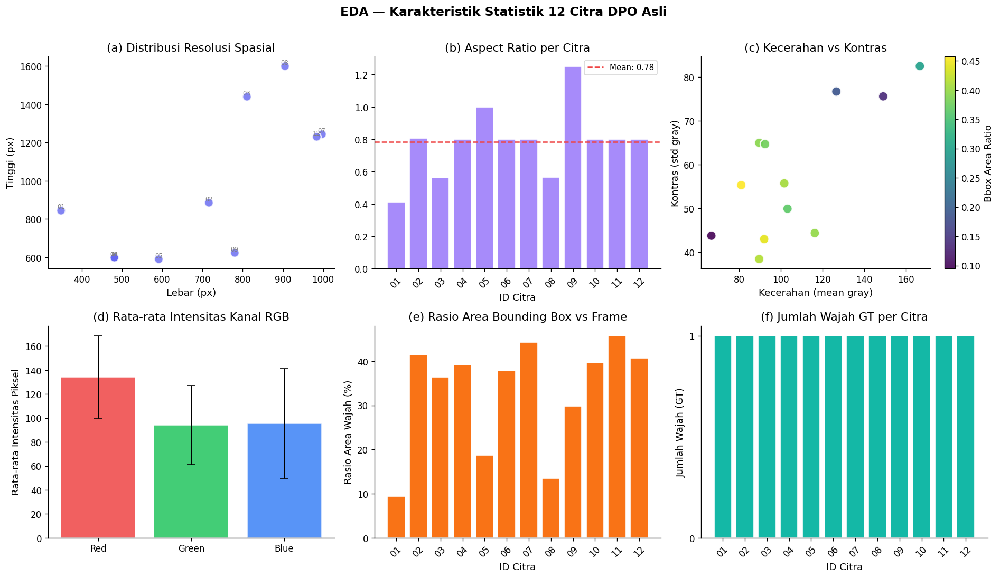

✅ Plot EDA statistik tersimpan.


In [7]:
# ============================================================
# CELL 3B: VISUALISASI STATISTIK
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('EDA — Karakteristik Statistik 12 Citra DPO Asli',
             fontsize=14, fontweight='bold', y=1.01)

# (a) Scatter resolusi
axes[0,0].scatter(df_eda['width'], df_eda['height'],
                  c='#6366F1', s=100, alpha=0.8, edgecolors='white', linewidths=1.5)
for _, row in df_eda.iterrows():
    axes[0,0].annotate(row['image'].replace('dpo_','').replace('.jpg',''),
                       (row['width'], row['height']), fontsize=7, ha='center', va='bottom', color='gray')
axes[0,0].set_xlabel('Lebar (px)')
axes[0,0].set_ylabel('Tinggi (px)')
axes[0,0].set_title('(a) Distribusi Resolusi Spasial')

# (b) Aspect ratio
axes[0,1].bar(df_eda['image'].str.replace('dpo_','').str.replace('.jpg',''),
              df_eda['aspect_ratio'], color='#A78BFA', edgecolor='white')
axes[0,1].axhline(df_eda['aspect_ratio'].mean(), color='#EF4444', ls='--', lw=1.5,
                   label=f'Mean: {df_eda["aspect_ratio"].mean():.2f}')
axes[0,1].set_title('(b) Aspect Ratio per Citra')
axes[0,1].set_xlabel('ID Citra')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(fontsize=9)

# (c) Kecerahan vs Kontras
sc = axes[0,2].scatter(df_eda['brightness'], df_eda['contrast'],
                        c=df_eda['avg_bbox_area_ratio'], cmap='viridis', s=120,
                        alpha=0.9, edgecolors='white', linewidths=1.5)
plt.colorbar(sc, ax=axes[0,2], label='Bbox Area Ratio')
axes[0,2].set_xlabel('Kecerahan (mean gray)')
axes[0,2].set_ylabel('Kontras (std gray)')
axes[0,2].set_title('(c) Kecerahan vs Kontras')

# (d) Mean RGB
for ch, label, col in zip(['mean_r','mean_g','mean_b'],
                            ['Red','Green','Blue'],
                            ['#EF4444','#22C55E','#3B82F6']):
    axes[1,0].bar(label, df_eda[ch].mean(), color=col, alpha=0.85, edgecolor='white',
                  yerr=df_eda[ch].std(), capsize=5)
axes[1,0].set_ylabel('Rata-rata Intensitas Piksel')
axes[1,0].set_title('(d) Rata-rata Intensitas Kanal RGB')

# (e) Bbox area ratio
axes[1,1].bar(df_eda['image'].str.replace('dpo_','').str.replace('.jpg',''),
              df_eda['avg_bbox_area_ratio'] * 100, color='#F97316', edgecolor='white')
axes[1,1].set_xlabel('ID Citra')
axes[1,1].set_ylabel('Rasio Area Wajah (%)')
axes[1,1].set_title('(e) Rasio Area Bounding Box vs Frame')
axes[1,1].tick_params(axis='x', rotation=45)

# (f) Jumlah wajah
axes[1,2].bar(df_eda['image'].str.replace('dpo_','').str.replace('.jpg',''),
              df_eda['n_faces'], color='#14B8A6', edgecolor='white')
axes[1,2].set_xlabel('ID Citra')
axes[1,2].set_ylabel('Jumlah Wajah (GT)')
axes[1,2].set_title('(f) Jumlah Wajah GT per Citra')
axes[1,2].yaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[1,2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(str(DIR_PLOTS / 'eda_statistics.png'), bbox_inches='tight', dpi=300)
plt.show()
print('✅ Plot EDA statistik tersimpan.')

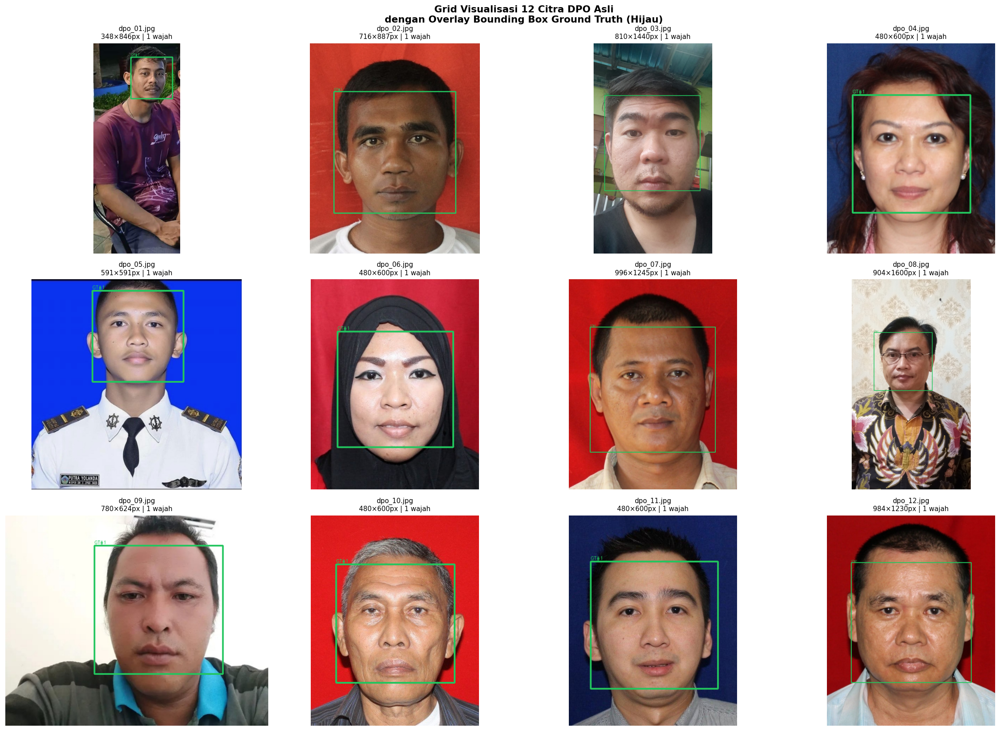

✅ Grid visualisasi GT tersimpan.


In [8]:
# ============================================================
# CELL 3C: GRID VISUALISASI 12 FOTO + GT BOUNDING BOX
# ============================================================
n_cols, n_rows = 4, 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 14))
fig.suptitle('Grid Visualisasi 12 Citra DPO Asli\ndengan Overlay Bounding Box Ground Truth (Hijau)',
             fontsize=13, fontweight='bold')

axes_flat  = axes.flatten()
img_names  = sorted(GT_DB.keys())

for ax, img_name in zip(axes_flat, img_names):
    gt_data = GT_DB[img_name]
    img_bgr = cv2.imread(str(DIR_ORIGINAL / img_name))
    if img_bgr is None:
        ax.set_visible(False)
        continue
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_ann = draw_bboxes_on_image(img_rgb, gt_data['bboxes'],
                                    color_rgb=(34, 197, 94), thickness=3)
    ax.imshow(img_ann)
    ax.set_title(f'{img_name}\n{gt_data["width"]}×{gt_data["height"]}px | {len(gt_data["bboxes"])} wajah',
                 fontsize=9)
    ax.axis('off')

for ax in axes_flat[len(img_names):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(str(DIR_PLOTS / 'grid_original_gt.png'), bbox_inches='tight', dpi=300)
plt.show()
print('✅ Grid visualisasi GT tersimpan.')

---
## Cell 4: Pipeline Augmentasi Data (Bounding Box-Preserving)

### Dasar Teori

Pustaka `albumentations` digunakan karena mendukung transformasi **bounding box sinkron** —
setiap transformasi spasial (rotasi, flip) secara otomatis memperbarui koordinat bounding box.
`BboxParams(format='pascal_voc')` memastikan format `[xmin, ymin, xmax, ymax]` dipertahankan.

### 10 Skenario Augmentasi

| # | Nama | Simulasi Kondisi |
|---|------|-----------------|
| 1 | Normal/Baseline | Foto asli tanpa modifikasi |
| 2 | Low Light | Kamera malam / ruangan redup |
| 3 | Overexposure | Cahaya balik / backlight |
| 4 | Gaussian Blur | Kamera defokus |
| 5 | Motion Blur | Target bergerak cepat |
| 6 | ISO Noise | Sensor kamera malam (high ISO) |
| 7 | JPEG Artifact | Screenshot / download kualitas rendah |
| 8 | Horizontal Flip | Variasi hadap kiri / kanan |
| 9 | Rotasi Ringan | Kemiringan kepala / kamera miring ±15° |
| 10 | Komposit | Low light + Noise + Blur |

In [9]:
# ============================================================
# CELL 4A: DEFINISI 10 PIPELINE AUGMENTASI
# ============================================================

BBOX_PARAMS = BboxParams(
    format='pascal_voc',
    label_fields=['class_labels'],
    min_visibility=0.3,
    min_area=100
)

AUGMENTATION_SCENARIOS = [
    {
        'name': 'normal',
        'label': '(1) Normal/Baseline',
        'transform': A.Compose([A.NoOp()], bbox_params=BBOX_PARAMS)
    },
    {
        'name': 'low_light',
        'label': '(2) Low Light',
        'transform': A.Compose([
            A.RandomBrightnessContrast(brightness_limit=(-0.45, -0.30),
                                       contrast_limit=(-0.2, 0.0), p=1.0)
        ], bbox_params=BBOX_PARAMS)
    },
    {
        'name': 'overexposure',
        'label': '(3) Overexposure',
        'transform': A.Compose([
            A.RandomBrightnessContrast(brightness_limit=(0.25, 0.40),
                                       contrast_limit=(0.0, 0.15), p=1.0)
        ], bbox_params=BBOX_PARAMS)
    },
    {
        'name': 'gaussian_blur',
        'label': '(4) Gaussian Blur',
        'transform': A.Compose([
            A.GaussianBlur(blur_limit=(7, 15), p=1.0)
        ], bbox_params=BBOX_PARAMS)
    },
    {
        'name': 'motion_blur',
        'label': '(5) Motion Blur',
        'transform': A.Compose([
            A.MotionBlur(blur_limit=(9, 19), p=1.0)
        ], bbox_params=BBOX_PARAMS)
    },
    {
        'name': 'iso_noise',
        'label': '(6) ISO Noise',
        'transform': A.Compose([
            A.GaussNoise(var_limit=(800, 2500), mean=0, p=1.0)
        ], bbox_params=BBOX_PARAMS)
    },
    {
        'name': 'jpeg_artifact',
        'label': '(7) JPEG Artifact',
        'transform': A.Compose([
            A.ImageCompression(quality_lower=5, quality_upper=20, p=1.0)
        ], bbox_params=BBOX_PARAMS)
    },
    {
        'name': 'horizontal_flip',
        'label': '(8) Horizontal Flip',
        'transform': A.Compose([
            A.HorizontalFlip(p=1.0)
        ], bbox_params=BBOX_PARAMS)
    },
    {
        'name': 'rotation',
        'label': '(9) Rotasi Ringan',
        'transform': A.Compose([
            A.Rotate(limit=15, border_mode=cv2.BORDER_REFLECT_101, p=1.0)
        ], bbox_params=BBOX_PARAMS)
    },
    {
        'name': 'composite',
        'label': '(10) Komposit',
        'transform': A.Compose([
            A.RandomBrightnessContrast(brightness_limit=(-0.35, -0.20), p=1.0),
            A.GaussNoise(var_limit=(400, 1200), mean=0, p=1.0),
            A.GaussianBlur(blur_limit=(3, 7), p=0.8),
        ], bbox_params=BBOX_PARAMS)
    },
]

print(f'✅ {len(AUGMENTATION_SCENARIOS)} skenario augmentasi didefinisikan.')
for s in AUGMENTATION_SCENARIOS:
    print(f'   {s["label"]}')

✅ 10 skenario augmentasi didefinisikan.
   (1) Normal/Baseline
   (2) Low Light
   (3) Overexposure
   (4) Gaussian Blur
   (5) Motion Blur
   (6) ISO Noise
   (7) JPEG Artifact
   (8) Horizontal Flip
   (9) Rotasi Ringan
   (10) Komposit


In [10]:
# ============================================================
# CELL 4B: EKSEKUSI AUGMENTASI — 12 × 10 = 120 CITRA
# ============================================================

def validate_bbox(bbox, img_w, img_h):
    """Clip & validasi koordinat bounding box agar sesuai batas gambar."""
    x1, y1, x2, y2 = bbox
    x1 = max(0, min(int(x1), img_w - 1))
    y1 = max(0, min(int(y1), img_h - 1))
    x2 = max(0, min(int(x2), img_w))
    y2 = max(0, min(int(y2), img_h))
    if x2 > x1 and y2 > y1 and (x2 - x1) * (y2 - y1) >= 100:
        return [x1, y1, x2, y2]
    return None


augmented_records = []

print('🔄 Memulai augmentasi 12 × 10 = 120 citra...')

for img_name in tqdm(sorted(GT_DB.keys()), desc='Gambar asli'):
    gt_data = GT_DB[img_name]
    img_bgr = cv2.imread(str(DIR_ORIGINAL / img_name))
    if img_bgr is None:
        print(f'  ⚠️ Lewati: {img_name}')
        continue
    
    img_rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    orig_bboxes = gt_data['bboxes']
    class_labels = ['face'] * len(orig_bboxes)
    
    for scenario in AUGMENTATION_SCENARIOS:
        base = img_name.replace('.jpg', '')
        aug_name = f'{base}_{scenario["name"]}.jpg'
        aug_path = DIR_AUGMENTED / aug_name
        
        try:
            augmented = scenario['transform'](
                image=img_rgb,
                bboxes=orig_bboxes,
                class_labels=class_labels
            )
            aug_img   = augmented['image']
            aug_bboxes_raw = augmented['bboxes']
            aug_h, aug_w   = aug_img.shape[:2]
            
            valid_bboxes = []
            for bbox in aug_bboxes_raw:
                v = validate_bbox(list(bbox), aug_w, aug_h)
                if v:
                    valid_bboxes.append(v)
            
            # Simpan gambar
            cv2.imwrite(str(aug_path),
                        cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR),
                        [cv2.IMWRITE_JPEG_QUALITY, 90])
            
            augmented_records.append({
                'aug_image': aug_name,
                'original_image': img_name,
                'scenario': scenario['name'],
                'scenario_label': scenario['label'],
                'aug_path': str(aug_path),
                'width': aug_w, 'height': aug_h,
                'bboxes': json.dumps(valid_bboxes),
                'n_gt_faces': len(valid_bboxes),
            })
        
        except Exception as e:
            print(f'  ❌ {img_name} | {scenario["name"]}: {e}')

df_aug = pd.DataFrame(augmented_records)
aug_csv = DIR_RESULTS / 'augmented_annotations.csv'
df_aug.to_csv(str(aug_csv), index=False)

print(f'\n✅ Augmentasi selesai!')
print(f'   Total citra : {len(df_aug)}')
print(f'   CSV tersimpan: {aug_csv}')
print(f'\n   Distribusi per skenario:')
print(df_aug.groupby('scenario_label')['n_gt_faces'].agg(['count','sum']).rename(
    columns={'count':'n_images','sum':'total_faces'}))

🔄 Memulai augmentasi 12 × 10 = 120 citra...


Gambar asli:   0%|          | 0/12 [00:00<?, ?it/s]

Gambar asli:  17%|█▋        | 2/12 [00:00<00:00, 14.12it/s]

Gambar asli:  33%|███▎      | 4/12 [00:00<00:00, 10.84it/s]

Gambar asli:  58%|█████▊    | 7/12 [00:00<00:00, 10.88it/s]

Gambar asli:  75%|███████▌  | 9/12 [00:00<00:00,  9.19it/s]

Gambar asli: 100%|██████████| 12/12 [00:01<00:00,  9.95it/s]

Gambar asli: 100%|██████████| 12/12 [00:01<00:00, 10.17it/s]


✅ Augmentasi selesai!
   Total citra : 120
   CSV tersimpan: D:\Kuliah\Semester 5\PCD\FaceDetection_FastMtCNN_MediaPipe\results\augmented_annotations.csv

   Distribusi per skenario:
                     n_images  total_faces
scenario_label                            
(1) Normal/Baseline        12           12
(10) Komposit              12           12
(2) Low Light              12           12
(3) Overexposure           12           12
(4) Gaussian Blur          12           12
(5) Motion Blur            12           12
(6) ISO Noise              12           12
(7) JPEG Artifact          12           12
(8) Horizontal Flip        12           12
(9) Rotasi Ringan          12           12


---
## Cell 5: EDA Pasca-Augmentasi & Verifikasi Integritas

Setelah augmentasi, tiga verifikasi kritis dilakukan:

1. **Validasi Koordinat** — Tidak ada bounding box out-of-bounds atau degenerate.
2. **Perbandingan Distribusi Kecerahan** — Konfirmasi augmentasi menciptakan keragaman pencahayaan.
3. **Visualisasi Sample Grid** — Tampilkan 10 variasi augmentasi dari 1 foto asli.

In [11]:
# ============================================================
# CELL 5A: VERIFIKASI INTEGRITAS BOUNDING BOX
# ============================================================
print('=== VERIFIKASI INTEGRITAS BOUNDING BOX ===')

issues = []
for _, row in df_aug.iterrows():
    bboxes = json.loads(row['bboxes'])
    w, h = row['width'], row['height']
    for bbox in bboxes:
        x1, y1, x2, y2 = bbox
        errs = []
        if x1 < 0 or y1 < 0 or x2 > w or y2 > h:
            errs.append('out-of-bounds')
        if x2 <= x1 or y2 <= y1:
            errs.append('degenerate')
        if (x2-x1)*(y2-y1) < 100:
            errs.append('too-small')
        if errs:
            issues.append({'image': row['aug_image'], 'bbox': bbox, 'issues': errs})

if issues:
    print(f'⚠️  {len(issues)} bounding box bermasalah ditemukan:')
    for iss in issues[:10]:
        print(f'   {iss}')
else:
    print(f'✅ Semua {df_aug["n_gt_faces"].sum()} bounding box valid!')
    print(f'   - Tidak ada koordinat out-of-bounds')
    print(f'   - Tidak ada bounding box degenerate')
    print(f'   - Semua luas > 100px²')

print(f'\n📊 Statistik GT pasca-augmentasi:')
print(f'   Total citra augmentasi  : {len(df_aug)}')
print(f'   Total bounding box GT   : {df_aug["n_gt_faces"].sum()}')
print(f'   Rata-rata wajah/citra   : {df_aug["n_gt_faces"].mean():.2f}')
print(f'   Citra tanpa wajah GT    : {(df_aug["n_gt_faces"]==0).sum()}')

=== VERIFIKASI INTEGRITAS BOUNDING BOX ===
✅ Semua 120 bounding box valid!
   - Tidak ada koordinat out-of-bounds
   - Tidak ada bounding box degenerate
   - Semua luas > 100px²

📊 Statistik GT pasca-augmentasi:
   Total citra augmentasi  : 120
   Total bounding box GT   : 120
   Rata-rata wajah/citra   : 1.00
   Citra tanpa wajah GT    : 0


Hitung kecerahan:   0%|          | 0/80 [00:00<?, ?it/s]

Hitung kecerahan:  14%|█▍        | 11/80 [00:00<00:00, 105.40it/s]

Hitung kecerahan:  29%|██▉       | 23/80 [00:00<00:00, 112.83it/s]

Hitung kecerahan:  44%|████▍     | 35/80 [00:00<00:00, 101.04it/s]

Hitung kecerahan:  57%|█████▊    | 46/80 [00:00<00:00, 96.80it/s] 

Hitung kecerahan:  72%|███████▎  | 58/80 [00:00<00:00, 102.58it/s]

Hitung kecerahan:  86%|████████▋ | 69/80 [00:00<00:00, 103.91it/s]

Hitung kecerahan: 100%|██████████| 80/80 [00:00<00:00, 104.72it/s]

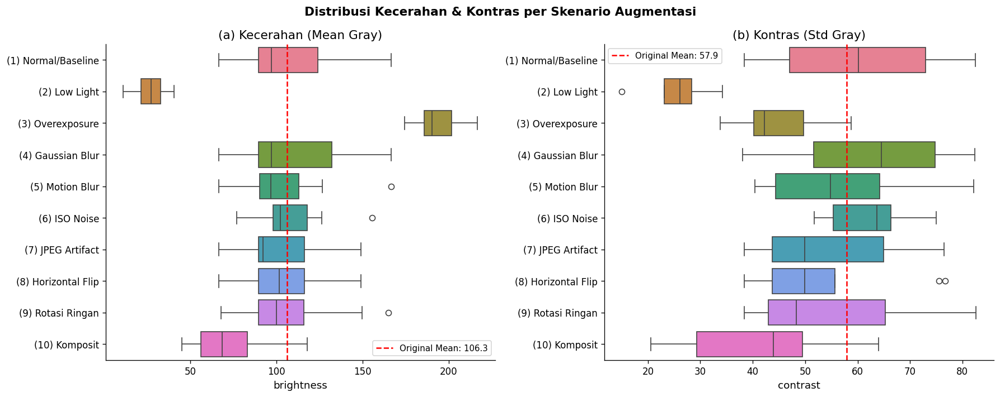

✅ Plot perbandingan kecerahan tersimpan.


In [12]:
# ============================================================
# CELL 5B: PERBANDINGAN DISTRIBUSI KECERAHAN
# ============================================================
aug_bright_records = []
sample_rows = df_aug.sample(min(80, len(df_aug)), random_state=SEED)

for _, row in tqdm(sample_rows.iterrows(), total=len(sample_rows), desc='Hitung kecerahan'):
    img = cv2.imread(row['aug_path'])
    if img is not None:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        aug_bright_records.append({
            'scenario': row['scenario_label'],
            'brightness': float(np.mean(gray)),
            'contrast': float(np.std(gray))
        })

df_ab = pd.DataFrame(aug_bright_records)
scenario_order = [s['label'] for s in AUGMENTATION_SCENARIOS]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Distribusi Kecerahan & Kontras per Skenario Augmentasi',
             fontsize=13, fontweight='bold')

orig_brightness_mean = df_eda['brightness'].mean()
orig_contrast_mean   = df_eda['contrast'].mean()

for ax, metric, orig_val, title in zip(
    axes,
    ['brightness', 'contrast'],
    [orig_brightness_mean, orig_contrast_mean],
    ['(a) Kecerahan (Mean Gray)', '(b) Kontras (Std Gray)']
):
    sns.boxplot(data=df_ab[df_ab['scenario'].isin(scenario_order)],
                y='scenario', x=metric, orient='h',
                palette='husl', ax=ax, order=scenario_order)
    ax.axvline(x=orig_val, color='red', ls='--', lw=1.5,
               label=f'Original Mean: {orig_val:.1f}')
    ax.set_title(title)
    ax.set_ylabel('')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(str(DIR_PLOTS / 'eda_augmentation_brightness.png'), bbox_inches='tight', dpi=300)
plt.show()
print('✅ Plot perbandingan kecerahan tersimpan.')

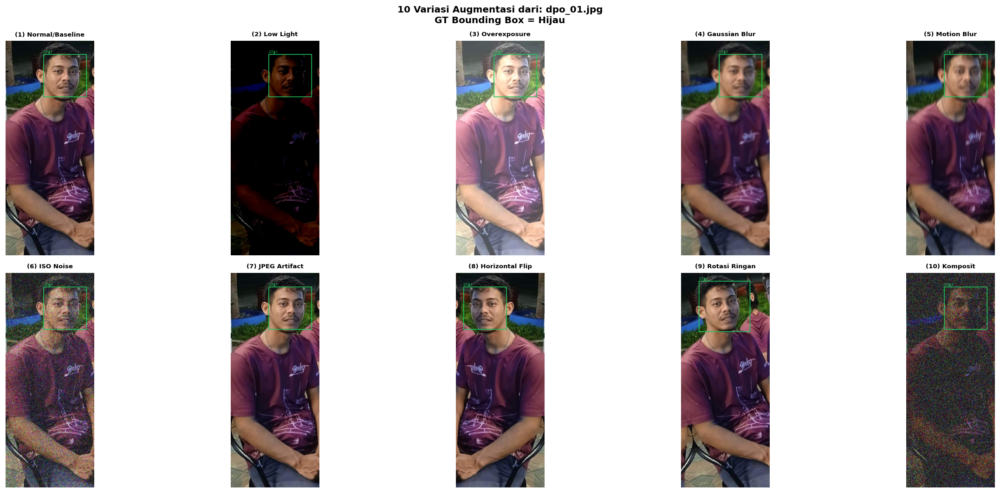

✅ Grid augmentasi sample tersimpan.


In [13]:
# ============================================================
# CELL 5C: VISUALISASI 10 VARIASI AUGMENTASI DARI 1 FOTO
# ============================================================
SAMPLE_IMG = sorted(GT_DB.keys())[0]
sample_aug_rows = df_aug[df_aug['original_image'] == SAMPLE_IMG]

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
fig.suptitle(f'10 Variasi Augmentasi dari: {SAMPLE_IMG}\nGT Bounding Box = Hijau',
             fontsize=12, fontweight='bold')

for ax, (_, row) in zip(axes.flatten(), sample_aug_rows.iterrows()):
    img_bgr = cv2.imread(row['aug_path'])
    if img_bgr is None:
        ax.set_visible(False)
        continue
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    bboxes = json.loads(row['bboxes'])
    annotated = draw_bboxes_on_image(img_rgb, bboxes, (34, 197, 94), thickness=2)
    ax.imshow(annotated)
    ax.set_title(row['scenario_label'], fontsize=8, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig(str(DIR_PLOTS / 'augmentation_sample_grid.png'), bbox_inches='tight', dpi=300)
plt.show()
print('✅ Grid augmentasi sample tersimpan.')

---
## Cell 6: Wrapper & Standarisasi Model Detektor

### Unified Interface Design

Kedua detektor diimplementasikan dengan **antarmuka yang seragam** untuk menjamin fairness benchmarking:

```python
result = detector.detect(image_rgb: np.ndarray) → DetectionResult
# DetectionResult: bboxes, scores, latency_ms
```

### Fast MTCNN
- **Arsitektur**: 3-stage Cascade CNN: P-Net → R-Net → O-Net
- **Library**: `facenet_pytorch.MTCNN(keep_all=True)`
- **Referensi**: Zhang et al. (2016), DeepFace implementation

### MediaPipe (BlazeFace)
- **Arsitektur**: Single-shot, anchor-based, mobile-optimized
- **model_selection=1**: Full-range — cocok untuk foto jarak jauh / DPO / CCTV
- **Konversi**: Koordinat normalisasi [0–1] → koordinat piksel absolut [xmin, ymin, xmax, ymax]

In [14]:
# ============================================================
# CELL 6A: DEFINISI DATACLASS & WRAPPER FAST MTCNN
# ============================================================
import torch

@dataclass
class DetectionResult:
    """Container standar untuk hasil deteksi wajah."""
    bboxes: List[List[int]] = field(default_factory=list)   # [[x1,y1,x2,y2], ...]
    scores: List[float]     = field(default_factory=list)    # confidence per deteksi
    latency_ms: float       = 0.0                            # waktu inferensi (ms)
    error: Optional[str]    = None                           # pesan error jika ada


class FastMTCNNDetector:
    """
    Wrapper detektor wajah berbasis MTCNN (facenet-pytorch).
    
    Arsitektur: 3-stage Cascade CNN — P-Net > R-Net > O-Net.
    Mendukung deteksi semua wajah (keep_all=True) dan bekerja
    pada CPU maupun GPU (CUDA).
    
    Referensi:
        Zhang, K. et al. (2016). Joint Face Detection and Alignment Using
        Multitask Cascaded Convolutional Networks. IEEE SPL.
    """
    
    def __init__(self, min_face_size=20, thresholds=None, device=None):
        self.device     = device or ('cuda' if torch.cuda.is_available() else 'cpu')
        self.thresholds = thresholds or [0.6, 0.7, 0.7]
        self.min_face_size = min_face_size
        self.model = None
        self._load_model()
    
    def _load_model(self):
        try:
            from facenet_pytorch import MTCNN
            self.model = MTCNN(
                keep_all=True,
                min_face_size=self.min_face_size,
                thresholds=self.thresholds,
                device=self.device,
                post_process=False
            )
            print(f'✅ FastMTCNN loaded | device={self.device} | min_face={self.min_face_size}px')
        except ImportError as e:
            print(f'❌ FastMTCNN gagal: {e}')
            self.model = None
    
    def detect(self, image_rgb: np.ndarray) -> DetectionResult:
        """
        Deteksi wajah pada citra RGB.
        
        Args:
            image_rgb: np.ndarray (H, W, 3), dtype=uint8, format RGB
        
        Returns:
            DetectionResult dengan bboxes dalam piksel absolut [xmin, ymin, xmax, ymax]
        """
        if self.model is None:
            return DetectionResult(error='Model tidak termuat')
        
        try:
            pil_img = Image.fromarray(image_rgb)
            
            t0 = time.perf_counter()
            boxes, probs = self.model.detect(pil_img)
            t1 = time.perf_counter()
            
            latency_ms = (t1 - t0) * 1000.0
            bboxes, scores = [], []
            
            if boxes is not None:
                h, w = image_rgb.shape[:2]
                for box, prob in zip(boxes, probs):
                    if prob is None or (isinstance(prob, float) and np.isnan(prob)):
                        continue
                    x1, y1, x2, y2 = box
                    x1, y1 = max(0, int(x1)), max(0, int(y1))
                    x2, y2 = min(w, int(x2)), min(h, int(y2))
                    if x2 > x1 and y2 > y1:
                        bboxes.append([x1, y1, x2, y2])
                        scores.append(float(prob))
            
            return DetectionResult(bboxes=bboxes, scores=scores, latency_ms=latency_ms)
        
        except Exception as e:
            return DetectionResult(error=str(e))

In [15]:
# ============================================================
# CELL 6B: WRAPPER MEDIAPIPE FACE DETECTION
# ============================================================

class MediaPipeDetector:
    """
    Wrapper detektor wajah berbasis MediaPipe BlazeFace.
    
    Dua mode operasi:
    - model_selection=0: short-range (selfie, jarak < 2m)
    - model_selection=1: full-range (foto jarak jauh, CCTV, DPO) ← direkomendasikan
    
    MediaPipe mengembalikan bounding box dalam koordinat normalisasi [0-1].
    Wrapper ini mengkonversi ke koordinat piksel absolut.
    
    Referensi:
        Bazarevsky, V. et al. (2019). BlazeFace: Sub-millisecond Neural 
        Face Detection on Mobile GPUs. arXiv:1907.05047.
    """
    
    def __init__(self, model_selection=1, min_detection_confidence=0.3):
        self.model_selection = model_selection
        self.min_detection_confidence = min_detection_confidence
        self.detector = None
        self._load_model()
    
    def _load_model(self):
        try:
            import mediapipe as mp
            self.mp = mp
            self.mp_face = mp.solutions.face_detection
            self.detector = self.mp_face.FaceDetection(
                model_selection=self.model_selection,
                min_detection_confidence=self.min_detection_confidence
            )
            mode = 'full-range' if self.model_selection == 1 else 'short-range'
            print(f'✅ MediaPipe loaded | mode={mode} | conf_thresh={self.min_detection_confidence}')
        except ImportError as e:
            print(f'❌ MediaPipe gagal: {e}')
            self.detector = None
    
    def detect(self, image_rgb: np.ndarray) -> DetectionResult:
        """
        Deteksi wajah pada citra RGB.
        
        Koordinat normalisasi [0-1] dikonversi ke piksel absolut [xmin, ymin, xmax, ymax].
        
        Args:
            image_rgb: np.ndarray (H, W, 3), dtype=uint8, format RGB
        
        Returns:
            DetectionResult dengan bboxes dalam piksel absolut
        """
        if self.detector is None:
            return DetectionResult(error='Model tidak termuat')
        
        try:
            h, w = image_rgb.shape[:2]
            
            t0 = time.perf_counter()
            results = self.detector.process(image_rgb)
            t1 = time.perf_counter()
            
            latency_ms = (t1 - t0) * 1000.0
            bboxes, scores = [], []
            
            if results.detections:
                for det in results.detections:
                    score = float(det.score[0]) if det.score else 0.0
                    bb = det.location_data.relative_bounding_box
                    
                    xmin = max(0, int(bb.xmin * w))
                    ymin = max(0, int(bb.ymin * h))
                    xmax = min(w, int((bb.xmin + bb.width) * w))
                    ymax = min(h, int((bb.ymin + bb.height) * h))
                    
                    if xmax > xmin and ymax > ymin:
                        bboxes.append([xmin, ymin, xmax, ymax])
                        scores.append(score)
            
            return DetectionResult(bboxes=bboxes, scores=scores, latency_ms=latency_ms)
        
        except Exception as e:
            return DetectionResult(error=str(e))
    
    def close(self):
        if self.detector:
            self.detector.close()


# -------------------------------------------------------
# Inisialisasi kedua detektor
# -------------------------------------------------------
print('--- Inisialisasi Detektor ---')
mtcnn_detector    = FastMTCNNDetector(min_face_size=20, thresholds=[0.6, 0.7, 0.7])
mediapipe_detector = MediaPipeDetector(model_selection=1, min_detection_confidence=0.3)

# Sanity check
print('\n--- Sanity Check (gambar pertama) ---')
test_name    = sorted(GT_DB.keys())[0]
test_img_bgr = cv2.imread(str(DIR_ORIGINAL / test_name))
test_img_rgb = cv2.cvtColor(test_img_bgr, cv2.COLOR_BGR2RGB)

r_mtcnn = mtcnn_detector.detect(test_img_rgb)
r_mp    = mediapipe_detector.detect(test_img_rgb)

print(f'FastMTCNN : {len(r_mtcnn.bboxes)} deteksi | {r_mtcnn.latency_ms:.1f}ms | err={r_mtcnn.error}')
print(f'MediaPipe : {len(r_mp.bboxes)} deteksi | {r_mp.latency_ms:.1f}ms | err={r_mp.error}')
print(f'GT        : {len(GT_DB[test_name]["bboxes"])} wajah')

--- Inisialisasi Detektor ---


✅ FastMTCNN loaded | device=cpu | min_face=20px


✅ MediaPipe loaded | mode=full-range | conf_thresh=0.3

--- Sanity Check (gambar pertama) ---
FastMTCNN : 1 deteksi | 64.2ms | err=None
MediaPipe : 1 deteksi | 7.0ms | err=None
GT        : 1 wajah


---
## Cell 7: Metrik Evaluasi & Benchmarking Engine

### Definisi Metrik

**Intersection over Union (IoU)**:
$$\text{IoU}(A, B) = \frac{|A \cap B|}{|A \cup B|}$$

**Matching Rule (PASCAL VOC standard)**:
- TP: IoU ≥ 0.5, satu GT hanya dapat di-match oleh satu prediksi (greedy matching).
- FP: Prediksi tanpa GT yang cocok.
- FN: GT yang tidak memiliki prediksi cocok.

$$\text{Precision} = \frac{TP}{TP + FP}, \quad \text{Recall} = \frac{TP}{TP + FN}, \quad F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$

**Latency & Throughput**:
$$\text{FPS} = \frac{1000}{\overline{\text{Latency (ms)}}}$$

In [16]:
# ============================================================
# CELL 7A: FUNGSI IoU & MATCHING
# ============================================================

def compute_iou(boxA: list, boxB: list) -> float:
    """
    Intersection over Union antara dua bounding box.
    
    Args:
        boxA, boxB: [xmin, ymin, xmax, ymax]
    
    Returns:
        float IoU ∈ [0, 1]
    """
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])
    
    inter = max(0, xB - xA) * max(0, yB - yA)
    if inter == 0:
        return 0.0
    
    areaA = max(0, boxA[2]-boxA[0]) * max(0, boxA[3]-boxA[1])
    areaB = max(0, boxB[2]-boxB[0]) * max(0, boxB[3]-boxB[1])
    union = areaA + areaB - inter
    
    return inter / union if union > 0 else 0.0


def match_detections_to_gt(pred_bboxes, gt_bboxes, iou_threshold=0.5):
    """
    Greedy matching prediksi → ground truth (PASCAL VOC style).
    
    Algoritma:
    1. Bangun matriks IoU (n_pred × n_gt).
    2. Secara iteratif pilih pair IoU tertinggi.
    3. Hapus baris & kolom yang sudah di-match.
    4. Hitung TP, FP, FN.
    
    Returns:
        dict: {tp, fp, fn, matched_ious}
    """
    n_pred = len(pred_bboxes)
    n_gt   = len(gt_bboxes)
    
    if n_gt == 0:
        return {'tp': 0, 'fp': n_pred, 'fn': 0, 'matched_ious': []}
    if n_pred == 0:
        return {'tp': 0, 'fp': 0, 'fn': n_gt, 'matched_ious': []}
    
    iou_matrix = np.zeros((n_pred, n_gt))
    for i, pred in enumerate(pred_bboxes):
        for j, gt in enumerate(gt_bboxes):
            iou_matrix[i, j] = compute_iou(pred, gt)
    
    matched_gt, matched_pred, matched_ious = set(), set(), []
    
    while True:
        if iou_matrix.max() < iou_threshold:
            break
        bi, bj = np.unravel_index(iou_matrix.argmax(), iou_matrix.shape)
        matched_pred.add(bi)
        matched_gt.add(bj)
        matched_ious.append(iou_matrix[bi, bj])
        iou_matrix[bi, :] = 0
        iou_matrix[:, bj] = 0
    
    tp = len(matched_pred)
    return {
        'tp': tp,
        'fp': n_pred - tp,
        'fn': n_gt - len(matched_gt),
        'matched_ious': matched_ious
    }


# --- Quick test IoU ---
b1, b2 = [10, 10, 110, 110], [60, 60, 160, 160]  # overlap = 50x50
expected = (50*50) / (100*100 + 100*100 - 50*50)
computed = compute_iou(b1, b2)
print(f'IoU test: computed={computed:.4f} expected={expected:.4f} → {"PASS" if abs(computed-expected)<1e-4 else "FAIL"}')

IoU test: computed=0.1429 expected=0.1429 → PASS


In [17]:
# ============================================================
# CELL 7B: BENCHMARKING LOOP UTAMA
# ============================================================

IOU_THRESHOLD = 0.5

DETECTORS = {
    'FastMTCNN': mtcnn_detector,
    'MediaPipe': mediapipe_detector,
}

eval_records = []

print(f'🔬 Benchmarking {len(df_aug)} citra augmentasi × {len(DETECTORS)} model...')
print(f'   IoU Threshold: {IOU_THRESHOLD}')

for _, row in tqdm(df_aug.iterrows(), total=len(df_aug), desc='Evaluasi'):
    gt_bboxes = json.loads(row['bboxes'])
    img_bgr = cv2.imread(row['aug_path'])
    
    if img_bgr is None:
        continue
    
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    for model_name, detector in DETECTORS.items():
        result = detector.detect(img_rgb)
        
        if result.error:
            eval_records.append({
                'model': model_name,
                'aug_image': row['aug_image'],
                'original_image': row['original_image'],
                'scenario': row['scenario'],
                'scenario_label': row['scenario_label'],
                'tp': 0, 'fp': 0, 'fn': len(gt_bboxes),
                'n_gt': len(gt_bboxes), 'n_pred': 0,
                'mean_iou': 0.0,
                'latency_ms': 0.0,
                'pred_bboxes': '[]',
                'error': result.error
            })
            continue
        
        match = match_detections_to_gt(result.bboxes, gt_bboxes, IOU_THRESHOLD)
        mean_iou = np.mean(match['matched_ious']) if match['matched_ious'] else 0.0
        
        eval_records.append({
            'model': model_name,
            'aug_image': row['aug_image'],
            'original_image': row['original_image'],
            'scenario': row['scenario'],
            'scenario_label': row['scenario_label'],
            'tp': match['tp'],
            'fp': match['fp'],
            'fn': match['fn'],
            'n_gt': len(gt_bboxes),
            'n_pred': len(result.bboxes),
            'mean_iou': round(float(mean_iou), 4),
            'latency_ms': round(result.latency_ms, 3),
            'pred_bboxes': json.dumps(result.bboxes),
            'error': None
        })

df_eval = pd.DataFrame(eval_records)
df_eval.to_csv(str(DIR_RESULTS / 'eval_raw_results.csv'), index=False)

print(f'\n✅ Benchmarking selesai! {len(df_eval)} record evaluasi.')
print(f'\n   Ringkasan cepat (sum):')
print(df_eval.groupby('model')[['tp','fp','fn','latency_ms']].agg({'tp':'sum','fp':'sum','fn':'sum','latency_ms':'mean'}).round(2))

🔬 Benchmarking 120 citra augmentasi × 2 model...
   IoU Threshold: 0.5


Evaluasi:   0%|          | 0/120 [00:00<?, ?it/s]

Evaluasi:   2%|▏         | 2/120 [00:00<00:06, 17.38it/s]

Evaluasi:   3%|▎         | 4/120 [00:00<00:06, 18.51it/s]

Evaluasi:   5%|▌         | 6/120 [00:00<00:06, 17.25it/s]

...

Evaluasi:  97%|█████████▋| 116/120 [00:10<00:00,  9.26it/s]

Evaluasi:  98%|█████████▊| 118/120 [00:10<00:00,  9.56it/s]

Evaluasi: 100%|██████████| 120/120 [00:11<00:00,  6.60it/s]

Evaluasi: 100%|██████████| 120/120 [00:11<00:00, 10.65it/s]


✅ Benchmarking selesai! 240 record evaluasi.

   Ringkasan cepat (sum):
            tp  fp  fn  latency_ms
model                             
FastMTCNN  119   6   1       82.43
MediaPipe  104   1  16        5.42


---
## Cell 8: Analisis Kuantitatif & Tabel Komparasi

### Pendekatan Agregasi: Micro-Averaging

Metrik dihitung dengan **micro-averaging** — menjumlahkan semua TP, FP, FN sebelum menghitung
Precision/Recall. Pendekatan ini memberikan gambaran performa keseluruhan yang lebih representatif
dibanding macro-averaging, terutama ketika distribusi jumlah wajah per gambar tidak merata.

In [18]:
# ============================================================
# CELL 8A: KALKULASI METRIK AGREGAT
# ============================================================

def compute_aggregate_metrics(df: pd.DataFrame, model_name: str) -> dict:
    """
    Hitung Precision, Recall, F1-Score, Avg IoU, Latency, FPS
    menggunakan micro-averaging untuk satu model.
    """
    dm = df[df['model'] == model_name]
    tp = dm['tp'].sum()
    fp = dm['fp'].sum()
    fn = dm['fn'].sum()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    
    tp_rows  = dm[dm['mean_iou'] > 0]
    avg_iou  = tp_rows['mean_iou'].mean() if len(tp_rows) > 0 else 0.0
    
    mean_lat = dm['latency_ms'].mean()
    fps      = 1000.0 / mean_lat if mean_lat > 0 else 0.0
    
    return {
        'Model': model_name,
        'Total TP': int(tp), 'Total FP': int(fp), 'Total FN': int(fn),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4),
        'F1-Score': round(f1, 4),
        'Avg IoU': round(float(avg_iou), 4),
        'Mean Latency (ms)': round(mean_lat, 2),
        'Throughput (FPS)': round(fps, 2),
    }

metrics_mtcnn = compute_aggregate_metrics(df_eval, 'FastMTCNN')
metrics_mp    = compute_aggregate_metrics(df_eval, 'MediaPipe')
df_comparison = pd.DataFrame([metrics_mtcnn, metrics_mp])

print('=' * 75)
print('TABEL KOMPARASI KINERJA: Fast MTCNN vs MediaPipe')
print('Dataset: DPO Bareskrim | 120 Citra Augmentasi | IoU Threshold=0.5')
print('=' * 75)
print(df_comparison.to_string(index=False))
print('=' * 75)

TABEL KOMPARASI KINERJA: Fast MTCNN vs MediaPipe
Dataset: DPO Bareskrim | 120 Citra Augmentasi | IoU Threshold=0.5
    Model  Total TP  Total FP  Total FN  Precision  Recall  F1-Score  Avg IoU  Mean Latency (ms)  Throughput (FPS)
FastMTCNN       119         6         1     0.9520  0.9917    0.9714   0.7475              82.43             12.13
MediaPipe       104         1        16     0.9905  0.8667    0.9244   0.7720               5.42            184.63



=== BREAKDOWN PERFORMA PER SKENARIO ===
                     F1-Score           Precision              Recall          
Model               FastMTCNN MediaPipe FastMTCNN MediaPipe FastMTCNN MediaPipe
Skenario                                                                       
(1) Normal/Baseline     1.000     1.000     1.000     1.000     1.000     1.000
(10) Komposit           0.889     0.800     0.800     1.000     1.000     0.667
(2) Low Light           0.957     1.000     1.000     1.000     0.917     1.000
(3) Overexposure        1.000     1.000     1.000     1.000     1.000     1.000
(4) Gaussian Blur       0.960     1.000     0.923     1.000     1.000     1.000
(5) Motion Blur         0.960     1.000     0.923     1.000     1.000     1.000
(6) ISO Noise           1.000     0.154     1.000     1.000     1.000     0.083
(7) JPEG Artifact       1.000     1.000     1.000     1.000     1.000     1.000
(8) Horizontal Flip     1.000     1.000     1.000     1.000     1.000     1.000

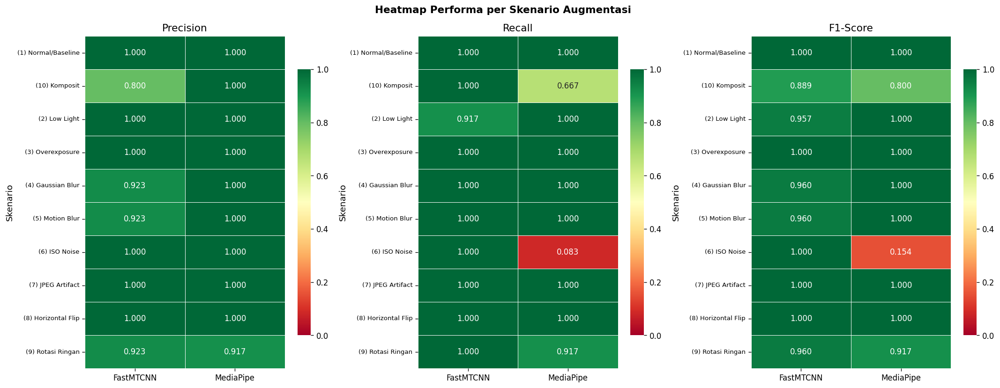

✅ Heatmap breakdown tersimpan.


In [19]:
# ============================================================
# CELL 8B: BREAKDOWN PER SKENARIO AUGMENTASI + HEATMAP
# ============================================================
breakdown_records = []

for sc_name in df_eval['scenario'].unique():
    df_sc = df_eval[df_eval['scenario'] == sc_name]
    sc_label = df_sc['scenario_label'].iloc[0]
    
    for model in ['FastMTCNN', 'MediaPipe']:
        dm = df_sc[df_sc['model'] == model]
        tp = dm['tp'].sum()
        fp = dm['fp'].sum()
        fn = dm['fn'].sum()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        avg_iou   = dm[dm['mean_iou'] > 0]['mean_iou'].mean()
        avg_lat   = dm['latency_ms'].mean()
        
        breakdown_records.append({
            'Skenario': sc_label, 'Model': model,
            'Precision': round(precision, 3),
            'Recall': round(recall, 3),
            'F1-Score': round(f1, 3),
            'Avg IoU': round(float(avg_iou) if not np.isnan(avg_iou) else 0.0, 3),
            'Latency (ms)': round(avg_lat, 2),
        })

df_breakdown = pd.DataFrame(breakdown_records)

# Pivot & print
df_pivot = df_breakdown.pivot_table(
    index='Skenario', columns='Model',
    values=['Precision', 'Recall', 'F1-Score'], aggfunc='first'
).round(3)
print('\n=== BREAKDOWN PERFORMA PER SKENARIO ===')
print(df_pivot.to_string())

# Heatmap
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
fig.suptitle('Heatmap Performa per Skenario Augmentasi', fontsize=13, fontweight='bold')

for ax, metric in zip(axes, ['Precision', 'Recall', 'F1-Score']):
    pivot_heat = df_breakdown.pivot_table(
        index='Skenario', columns='Model', values=metric, aggfunc='first'
    )
    sns.heatmap(pivot_heat, annot=True, fmt='.3f', cmap='RdYlGn',
                vmin=0, vmax=1, ax=ax, linewidths=0.5, cbar_kws={'shrink': 0.8})
    ax.set_title(f'{metric}')
    ax.set_xlabel('')
    ax.tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.savefig(str(DIR_PLOTS / 'heatmap_breakdown.png'), bbox_inches='tight', dpi=300)
plt.show()
print('✅ Heatmap breakdown tersimpan.')

---
## Cell 9: Visualisasi Kualitatif & Analisis Error (Failure Cases)

Analisis ini menjawab:
- **Secara visual**, di mana kedua model setuju/berbeda dengan ground truth?
- **Kondisi augmentasi mana** yang menyebabkan failure (FN/FP) terbanyak?
- **Studi kasus kegagalan**: gambar spesifik yang memicu false negative.

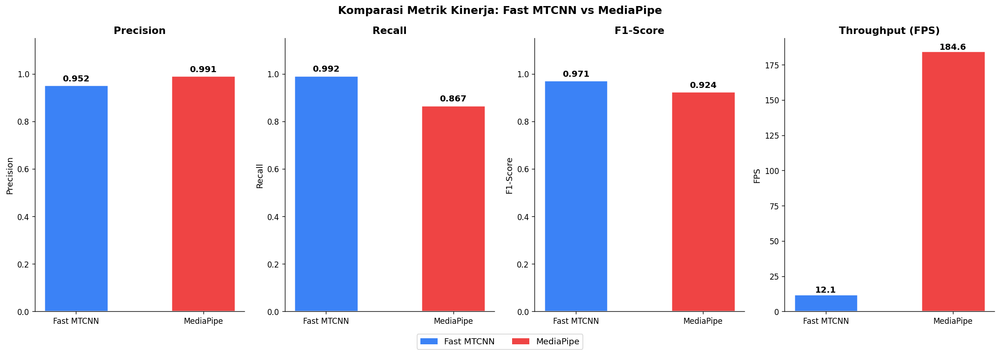

✅ Bar chart tersimpan.


In [20]:
# ============================================================
# CELL 9A: BAR CHART KOMPARASI METRIK
# ============================================================
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 4, figsize=(18, 6))
fig.suptitle('Komparasi Metrik Kinerja: Fast MTCNN vs MediaPipe',
             fontsize=14, fontweight='bold')

metric_info = [
    ('Precision', 'Precision', True),
    ('Recall', 'Recall', True),
    ('F1-Score', 'F1-Score', True),
    ('Throughput (FPS)', 'FPS', False),
]
colors = [PALETTE['FastMTCNN'], PALETTE['MediaPipe']]

for ax, (metric, ylabel, is_ratio) in zip(axes, metric_info):
    vals = df_comparison[metric].values
    bars = ax.bar(['Fast MTCNN', 'MediaPipe'], vals,
                  color=colors, edgecolor='white', linewidth=1.5, width=0.5)
    for bar, val in zip(bars, vals):
        fmt = f'{val:.3f}' if is_ratio else f'{val:.1f}'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                fmt, ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(ylabel)
    if is_ratio:
        ax.set_ylim(0, 1.15)

legend_elements = [Patch(facecolor=PALETTE['FastMTCNN'], label='Fast MTCNN'),
                   Patch(facecolor=PALETTE['MediaPipe'], label='MediaPipe')]
fig.legend(handles=legend_elements, loc='lower center', ncol=2, fontsize=11,
           bbox_to_anchor=(0.5, -0.06))

plt.tight_layout()
plt.savefig(str(DIR_PLOTS / 'metric_comparison_bar.png'), bbox_inches='tight', dpi=300)
plt.show()
print('✅ Bar chart tersimpan.')

🖼️  Generating side-by-side visualisasi...


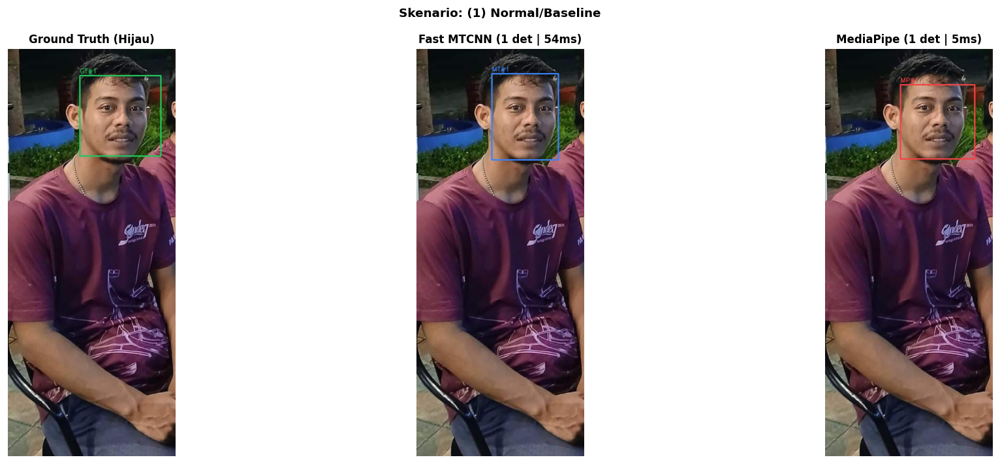

   ✅ sidebyside_normal.png


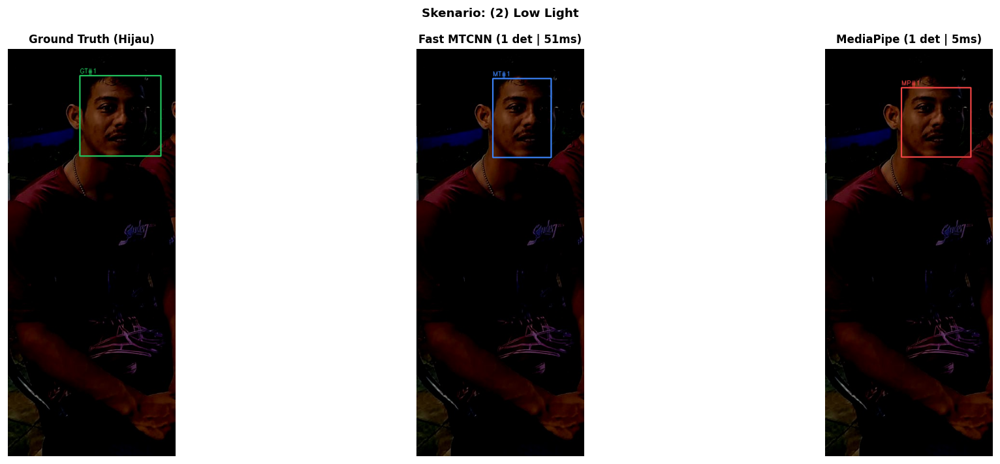

   ✅ sidebyside_low_light.png


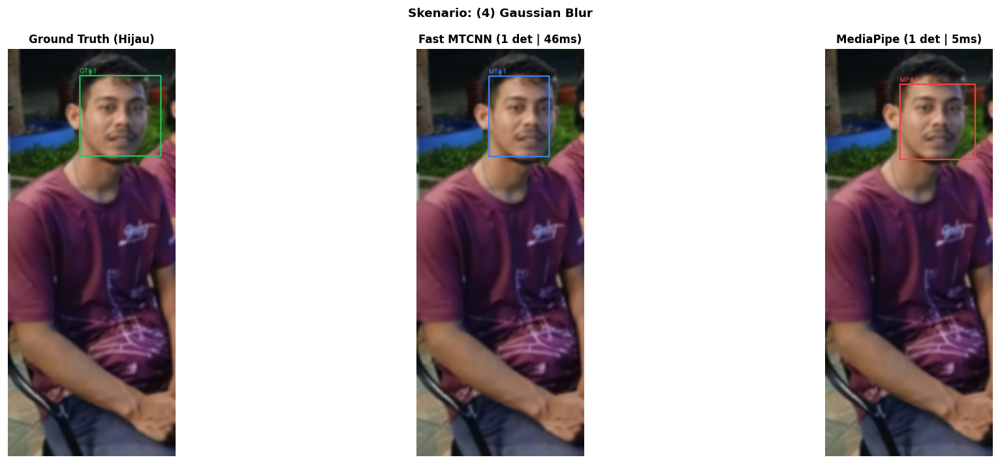

   ✅ sidebyside_gaussian_blur.png


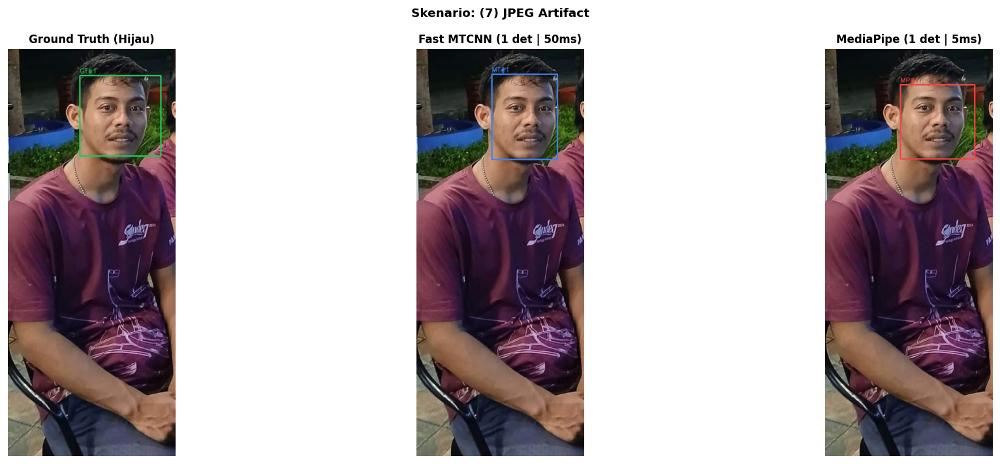

   ✅ sidebyside_jpeg_artifact.png


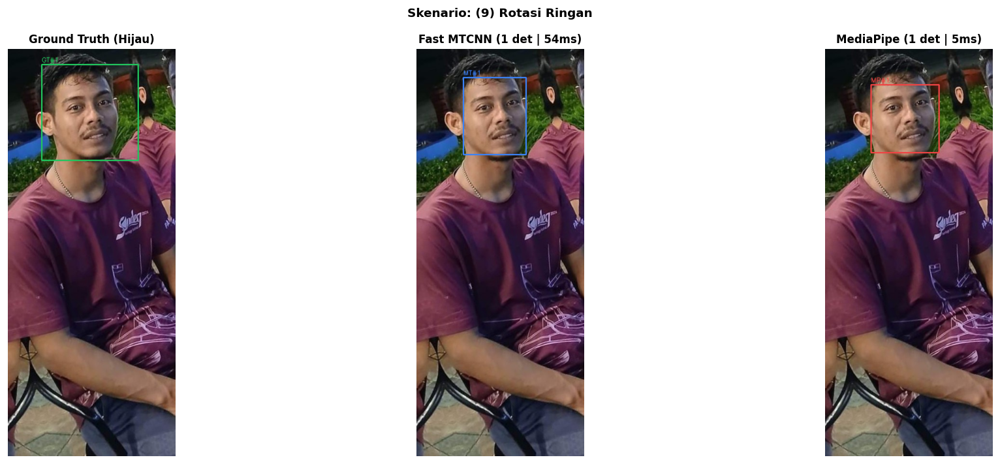

   ✅ sidebyside_rotation.png


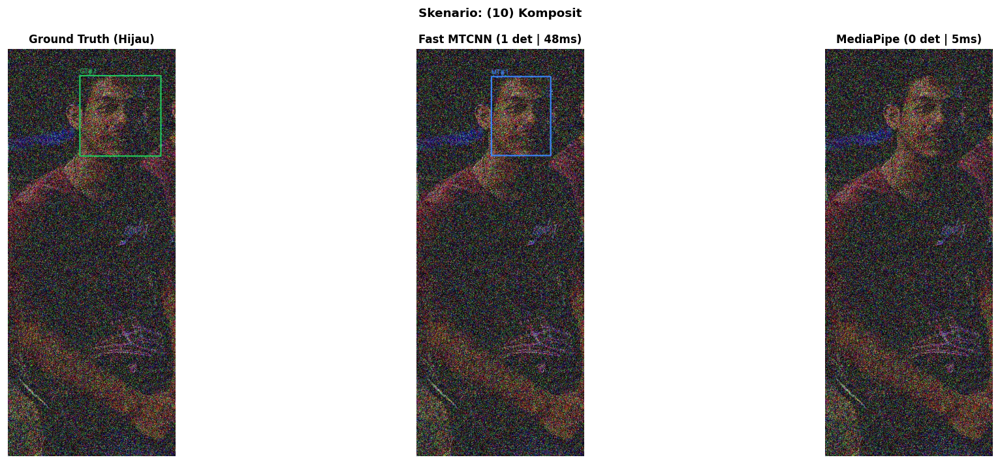

   ✅ sidebyside_composite.png


In [21]:
# ============================================================
# CELL 9B: SIDE-BY-SIDE DETEKSI (GT vs MTCNN vs MediaPipe)
# ============================================================

def visualize_side_by_side(img_rgb, gt_bboxes, r_mtcnn, r_mp,
                             title='', save_path=None):
    """3-panel: GT (hijau) | MTCNN (biru) | MediaPipe (merah)."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(title, fontsize=11, fontweight='bold')
    
    panels = [
        ('Ground Truth (Hijau)', gt_bboxes, (34, 197, 94), 'GT'),
        (f'Fast MTCNN ({len(r_mtcnn.bboxes)} det | {r_mtcnn.latency_ms:.0f}ms)',
         r_mtcnn.bboxes, (59, 130, 246), 'MT'),
        (f'MediaPipe ({len(r_mp.bboxes)} det | {r_mp.latency_ms:.0f}ms)',
         r_mp.bboxes, (239, 68, 68), 'MP'),
    ]
    
    for ax, (panel_title, bboxes, color, pfx) in zip(axes, panels):
        ann = draw_bboxes_on_image(img_rgb, bboxes, color_rgb=color, thickness=2,
                                    label_prefix=pfx)
        ax.imshow(ann)
        ax.set_title(panel_title, fontsize=10, fontweight='bold')
        ax.axis('off')
    
    plt.tight_layout()
    if save_path:
        plt.savefig(str(save_path), bbox_inches='tight', dpi=300)
    plt.show()
    plt.close()


sample_scenarios = ['normal', 'low_light', 'gaussian_blur',
                     'jpeg_artifact', 'rotation', 'composite']
sample_orig = sorted(GT_DB.keys())[0]

print('🖼️  Generating side-by-side visualisasi...')
for scenario in sample_scenarios:
    s_row = df_aug[(df_aug['original_image'] == sample_orig) &
                    (df_aug['scenario'] == scenario)]
    if len(s_row) == 0:
        continue
    row = s_row.iloc[0]
    img_bgr = cv2.imread(row['aug_path'])
    if img_bgr is None:
        continue
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    gt_bboxes = json.loads(row['bboxes'])
    r1 = mtcnn_detector.detect(img_rgb)
    r2 = mediapipe_detector.detect(img_rgb)
    visualize_side_by_side(img_rgb, gt_bboxes, r1, r2,
                            title=f'Skenario: {row["scenario_label"]}',
                            save_path=DIR_PLOTS / f'sidebyside_{scenario}.png')
    print(f'   ✅ sidebyside_{scenario}.png')

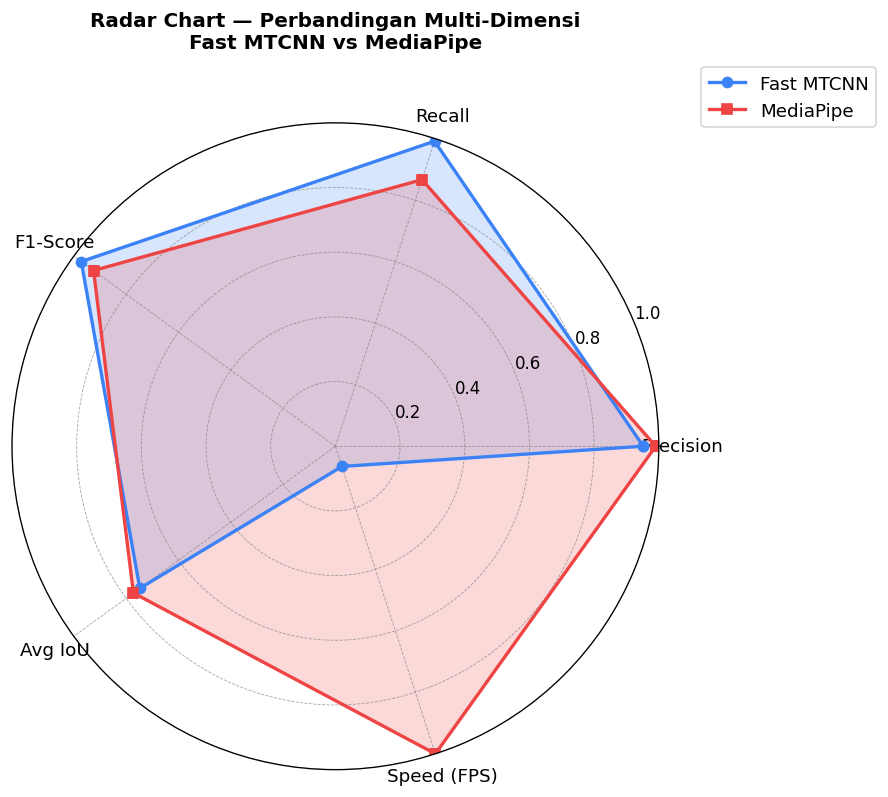

✅ Radar chart tersimpan.


In [22]:
# ============================================================
# CELL 9C: RADAR CHART PERBANDINGAN MULTI-DIMENSI
# ============================================================
max_fps = max(metrics_mtcnn['Throughput (FPS)'], metrics_mp['Throughput (FPS)'], 1.0)
categories = ['Precision', 'Recall', 'F1-Score', 'Avg IoU', 'Speed (FPS)']
N = len(categories)

v_mtcnn = [metrics_mtcnn['Precision'], metrics_mtcnn['Recall'],
            metrics_mtcnn['F1-Score'], metrics_mtcnn['Avg IoU'],
            metrics_mtcnn['Throughput (FPS)'] / max_fps]
v_mp = [metrics_mp['Precision'], metrics_mp['Recall'],
         metrics_mp['F1-Score'], metrics_mp['Avg IoU'],
         metrics_mp['Throughput (FPS)'] / max_fps]

v_mtcnn += v_mtcnn[:1]; v_mp += v_mp[:1]
angles = [n / N * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
ax.plot(angles, v_mtcnn, 'o-', lw=2, color=PALETTE['FastMTCNN'], label='Fast MTCNN')
ax.fill(angles, v_mtcnn, alpha=0.2, color=PALETTE['FastMTCNN'])
ax.plot(angles, v_mp, 's-', lw=2, color=PALETTE['MediaPipe'], label='MediaPipe')
ax.fill(angles, v_mp, alpha=0.2, color=PALETTE['MediaPipe'])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, size=11)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.grid(color='gray', ls='--', lw=0.5, alpha=0.7)
ax.set_title('Radar Chart — Perbandingan Multi-Dimensi\nFast MTCNN vs MediaPipe',
             size=12, fontweight='bold', y=1.1)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=11)
plt.savefig(str(DIR_PLOTS / 'radar_chart.png'), bbox_inches='tight', dpi=300)
plt.show()
print('✅ Radar chart tersimpan.')

=== ANALISIS KASUS KEGAGALAN ===

FastMTCNN: 1 FN dari 120 gambar
   Breakdown FN per skenario:
     (2) Low Light: 1 FN


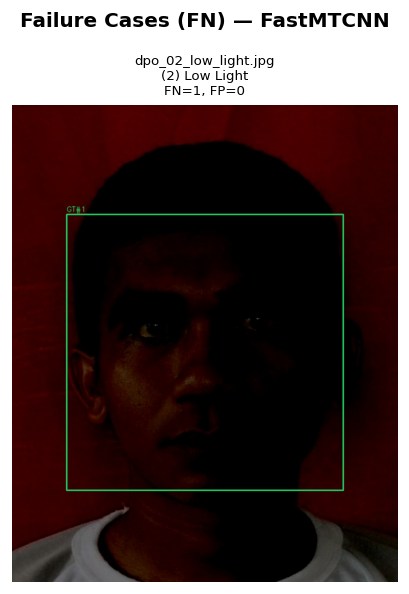

   Plot tersimpan: failure_fastmtcnn.png

MediaPipe: 16 FN dari 120 gambar
   Breakdown FN per skenario:
     (6) ISO Noise: 11 FN
     (10) Komposit: 4 FN
     (9) Rotasi Ringan: 1 FN


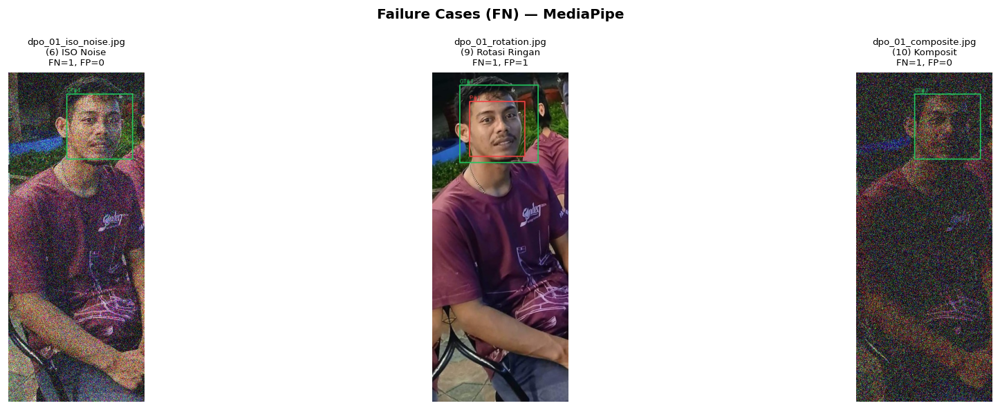

   Plot tersimpan: failure_mediapipe.png


In [23]:
# ============================================================
# CELL 9D: FAILURE CASE ANALYSIS
# ============================================================
print('=== ANALISIS KASUS KEGAGALAN ===')

for model_name in ['FastMTCNN', 'MediaPipe']:
    dm_fn = df_eval[(df_eval['model'] == model_name) & (df_eval['fn'] > 0)]
    
    total_fn = dm_fn['fn'].sum()
    total_img = len(df_eval[df_eval['model'] == model_name])
    
    print(f'\n{model_name}: {total_fn} FN dari {total_img} gambar')
    print(f'   Breakdown FN per skenario:')
    fn_by_sc = dm_fn.groupby('scenario_label')['fn'].sum().sort_values(ascending=False)
    for sc, val in fn_by_sc.items():
        print(f'     {sc}: {val} FN')
    
    worst = dm_fn.nlargest(3, 'fn')
    if len(worst) == 0:
        print(f'  ✅ Tidak ada False Negative!')
        continue
    
    n_show = min(3, len(worst))
    color  = (59, 130, 246) if model_name == 'FastMTCNN' else (239, 68, 68)
    fig, axes = plt.subplots(1, n_show, figsize=(6*n_show, 5))
    if n_show == 1:
        axes = [axes]
    fig.suptitle(f'Failure Cases (FN) — {model_name}', fontsize=12, fontweight='bold')
    
    for ax, (_, wrow) in zip(axes, worst.iterrows()):
        aug_match = df_aug[df_aug['aug_image'] == wrow['aug_image']]
        if len(aug_match) == 0:
            continue
        arow = aug_match.iloc[0]
        img_bgr = cv2.imread(arow['aug_path'])
        if img_bgr is None:
            continue
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        gt_bboxes   = json.loads(arow['bboxes'])
        pred_bboxes = json.loads(wrow['pred_bboxes'])
        img_ann = draw_bboxes_on_image(img_rgb, gt_bboxes, (34,197,94), 2, 'GT')
        img_ann = draw_bboxes_on_image(img_ann, pred_bboxes, color, 2, 'P')
        ax.imshow(img_ann)
        ax.set_title(f'{wrow["aug_image"]}\n{wrow["scenario_label"]}\nFN={wrow["fn"]}, FP={wrow["fp"]}',
                     fontsize=8)
        ax.axis('off')
    
    plt.tight_layout()
    plt.savefig(str(DIR_PLOTS / f'failure_{model_name.lower()}.png'), bbox_inches='tight', dpi=300)
    plt.show()
    plt.close()
    print(f'   Plot tersimpan: failure_{model_name.lower()}.png')

---
## Cell 10: Ekspor Hasil Penelitian

Semua tabel evaluasi dan ringkasan diekspor dalam format yang siap digunakan
untuk penulisan naskah Bab 4 (Hasil dan Pembahasan) format jurnal ilmiah.

In [24]:
# ============================================================
# CELL 10: EKSPOR HASIL PENELITIAN
# ============================================================

# 10.1 Tabel komparasi utama
df_comparison.to_csv(str(DIR_RESULTS / 'results_comparison.csv'), index=False)
print(f'✅ results_comparison.csv')

# 10.2 Breakdown per skenario
df_breakdown.to_csv(str(DIR_RESULTS / 'results_breakdown_by_scenario.csv'), index=False)
print(f'✅ results_breakdown_by_scenario.csv')

# 10.3 Raw eval results
df_eval.to_csv(str(DIR_RESULTS / 'eval_raw_results.csv'), index=False)
print(f'✅ eval_raw_results.csv')

# 10.4 Ringkasan JSON
summary = {
    'experiment': 'Fast MTCNN vs MediaPipe — DPO Bareskrim',
    'system_hardware': SYSTEM_INFO,
    'seed': SEED,
    'dataset': {
        'n_original': len(GT_DB),
        'n_augmented': len(df_aug),
        'augmentation_scenarios': [s['name'] for s in AUGMENTATION_SCENARIOS],
        'iou_threshold': IOU_THRESHOLD,
    },
    'results': {
        'FastMTCNN': metrics_mtcnn,
        'MediaPipe': metrics_mp,
    },
    'winner': {
        'accuracy_f1': 'FastMTCNN' if metrics_mtcnn['F1-Score'] >= metrics_mp['F1-Score'] else 'MediaPipe',
        'speed_fps':   'FastMTCNN' if metrics_mtcnn['Throughput (FPS)'] >= metrics_mp['Throughput (FPS)'] else 'MediaPipe',
    }
}

with open(str(DIR_RESULTS / 'experiment_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2, default=str)
print(f'✅ experiment_summary.json')

# 10.5 Ringkasan akhir di console
print('\n' + '='*72)
print('RINGKASAN AKHIR EKSPERIMEN')
print(f"Hardware: {SYSTEM_INFO['cpu_model']} | {SYSTEM_INFO['ram_total_gb']} GB RAM | OS: {SYSTEM_INFO['os']}")
print('='*72)
print(f'{"Metrik":<26} {"Fast MTCNN":>14} {"MediaPipe":>14} {"Pemenang":>14}')
print('-'*72)

for metric in ['Precision','Recall','F1-Score','Avg IoU','Mean Latency (ms)','Throughput (FPS)']:
    vm = metrics_mtcnn[metric]
    vp = metrics_mp[metric]
    if metric == 'Mean Latency (ms)':
        winner = 'FastMTCNN ✓' if vm <= vp else 'MediaPipe ✓'
    else:
        winner = 'FastMTCNN ✓' if vm >= vp else 'MediaPipe ✓'
    fmt = '.4f' if isinstance(vm, float) and vm < 100 else '.1f'
    print(f'{metric:<26} {vm:>14{fmt}} {vp:>14{fmt}} {winner:>14}')

print('='*72)
print(f'\n🏆 Akurasi (F1) terbaik : {summary["winner"]["accuracy_f1"]}')
print(f'⚡ Kecepatan (FPS) terbaik: {summary["winner"]["speed_fps"]}')


✅ results_comparison.csv
✅ results_breakdown_by_scenario.csv
✅ eval_raw_results.csv
✅ experiment_summary.json

RINGKASAN AKHIR EKSPERIMEN
Hardware: Intel(R) Core(TM) Ultra 7 255HX | 31.43 GB RAM | OS: Windows 11 (64bit)
Metrik                         Fast MTCNN      MediaPipe       Pemenang
------------------------------------------------------------------------
Precision                          0.9520         0.9905    MediaPipe ✓
Recall                             0.9917         0.8667    FastMTCNN ✓
F1-Score                           0.9714         0.9244    FastMTCNN ✓
Avg IoU                            0.7475         0.7720    MediaPipe ✓
Mean Latency (ms)                 82.4300         5.4200    MediaPipe ✓
Throughput (FPS)                  12.1300       184.6300    MediaPipe ✓

🏆 Akurasi (F1) terbaik : FastMTCNN
⚡ Kecepatan (FPS) terbaik: MediaPipe


In [25]:
# Daftar semua file output
print('\n📦 FILE OUTPUT PENELITIAN:')
print('-' * 60)
for f in sorted(DIR_RESULTS.rglob('*')):
    if f.is_file():
        kb = f.stat().st_size / 1024
        print(f'  {str(f.relative_to(DIR_RESULTS)):<45} {kb:>8.1f} KB')
print('-' * 60)
print('\n✅ Notebook selesai dieksekusi!')



📦 FILE OUTPUT PENELITIAN:
------------------------------------------------------------
  augmented_annotations.csv                         23.2 KB
  eval_raw_results.csv                              28.4 KB
  experiment_summary.json                            1.3 KB
  ground_truth.json                                  2.5 KB
  plots\augmentation_sample_grid.png              8221.3 KB
  plots\eda_augmentation_brightness.png            230.5 KB
  plots\eda_statistics.png                         458.1 KB
  plots\failure_fastmtcnn.png                      456.1 KB
  plots\failure_mediapipe.png                     4311.7 KB
  plots\grid_original_gt.png                     11730.2 KB
  plots\heatmap_breakdown.png                      279.3 KB
  plots\metric_comparison_bar.png                  189.2 KB
  plots\radar_chart.png                            403.3 KB
  plots\sidebyside_composite.png                  2901.9 KB
  plots\sidebyside_gaussian_blur.png               902.8 KB
  plots\side

---
## Referensi

1. Zhang, K., et al. (2016). **Joint Face Detection and Alignment Using Multitask Cascaded Convolutional Networks**. *IEEE Signal Processing Letters*, 23(10), 1499–1503.

2. Lugaresi, C., et al. (2019). **MediaPipe: A Framework for Building Perception Pipelines**. *arXiv:1906.08172*.

3. Bazarevsky, V., et al. (2019). **BlazeFace: Sub-millisecond Neural Face Detection on Mobile GPUs**. *arXiv:1907.05047*.

4. Serengil, S.I., & Ozpinar, A. (2020). **LightFace: A Hybrid Deep Face Recognition Framework**. *IEEE ASYU 2020*.

5. DeepFace — Face Detection Models: https://github.com/serengil/deepface/tree/master/deepface/models/face_detection

6. Buslaev, A., et al. (2020). **Albumentations: Fast and Flexible Image Augmentations**. *Information*, 11(2), 125.

7. Everingham, M., et al. (2010). **The Pascal Visual Object Classes (VOC) Challenge**. *IJCV*, 88(2), 303–338.

---
*Notebook dikembangkan untuk penelitian Pengolahan Citra Digital (PCD), Universitas Dian Nuswantoro.*